In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

In [7]:
path = kagglehub.dataset_download("asinow/car-price-dataset")
csv_file = f"{path}/car_price_dataset.csv"
df = pd.read_csv(csv_file)

In [8]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Brand         10000 non-null  object 
 1   Model         10000 non-null  object 
 2   Year          10000 non-null  int64  
 3   Engine_Size   10000 non-null  float64
 4   Fuel_Type     10000 non-null  object 
 5   Transmission  10000 non-null  object 
 6   Mileage       10000 non-null  int64  
 7   Doors         10000 non-null  int64  
 8   Owner_Count   10000 non-null  int64  
 9   Price         10000 non-null  int64  
dtypes: float64(1), int64(5), object(4)
memory usage: 781.4+ KB
None


Berdasarkan data diatas, ada beberapa kesimpulan yang dapat diambil:
- 10000 jumlah baris data dan 10 kolom data
- Jenis data ada 2 yaitu: Numerik(6 kolom) dan Kategorikal(4 kolom)
- Tidak ada missing value

In [9]:
print(df.describe())

               Year   Engine_Size        Mileage         Doors   Owner_Count  \
count  10000.000000  10000.000000   10000.000000  10000.000000  10000.000000   
mean    2011.543700      3.000560  149239.111800      3.497100      2.991100   
std        6.897699      1.149324   86322.348957      1.110097      1.422682   
min     2000.000000      1.000000      25.000000      2.000000      1.000000   
25%     2006.000000      2.000000   74649.250000      3.000000      2.000000   
50%     2012.000000      3.000000  149587.000000      3.000000      3.000000   
75%     2017.000000      4.000000  223577.500000      4.000000      4.000000   
max     2023.000000      5.000000  299947.000000      5.000000      5.000000   

             Price  
count  10000.00000  
mean    8852.96440  
std     3112.59681  
min     2000.00000  
25%     6646.00000  
50%     8858.50000  
75%    11086.50000  
max    18301.00000  


Penjelasan:
- count : Jumlah data
- mean  : Rata rata dari semua data
- std   : Mengukur seberapa besar penyebaran atau variasi data terhadap rata
- min   : Nilai terkecil dalam kolom
- 25%   : 25% data berada di bawah nilai ini
- 50%   : Titik tengah data
- 75%   : 75% data berada di bawah nilai ini
- max   : Nilai terbesar dalam kolom

In [10]:
print(df.isnull().sum())

Brand           0
Model           0
Year            0
Engine_Size     0
Fuel_Type       0
Transmission    0
Mileage         0
Doors           0
Owner_Count     0
Price           0
dtype: int64


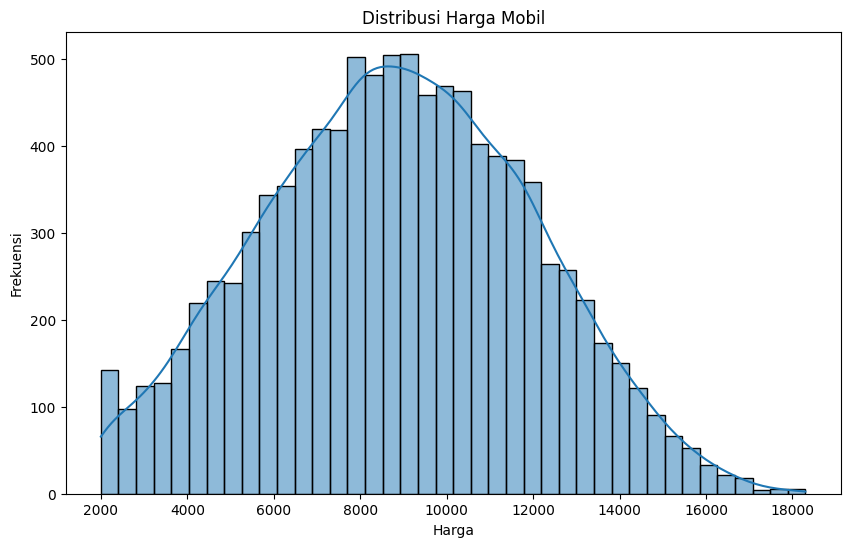

In [12]:
plt.figure(figsize=(10, 6))
sns.histplot(df['Price'], kde=True)
plt.title('Distribusi Harga Mobil')
plt.xlabel('Harga')
plt.ylabel('Frekuensi')
plt.show()

Berdasarkan grafik tersebut dapat kita ambil kesimpulan bahwa rentang harga 8000 dollar ke 10000 dollar memiliki frekuensi tertinggi.

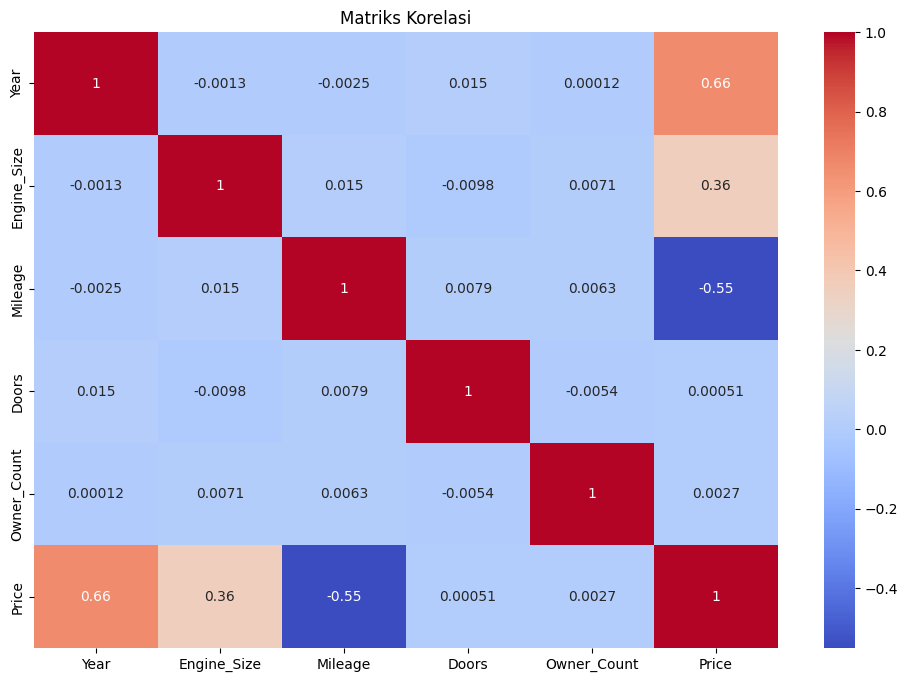

In [14]:
plt.figure(figsize=(12, 8))
numeric_df = df.select_dtypes(include=['number'])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm')
plt.title('Matriks Korelasi')
plt.show()

Warna:
- Merah Terang: Korelasi positif kuat.
- Biru Gelap: Korelasi negatif kuat.
- Putih/Pucat: Hubungan lemah atau tidak ada korelasi.

Berdasarkan grafik diatas dapat diambil kesimpulan bahwa faktor yang paling mempengaruhi harga mobil adalah tahun, engine size, dan jarak tempuh. Tahun adalah faktor korelasi positif yang kuat, artinya apabila mobil tersebut adalah keluaran terbaru(tahun tinggi) harga akan meningkat. Sedangkan jarak tempuh(mileage) adalah faktor korelasi negatif kuat untuk harga. semakin tinggi jarak tempuhnya maka akan semakin murah harga mobilnya.

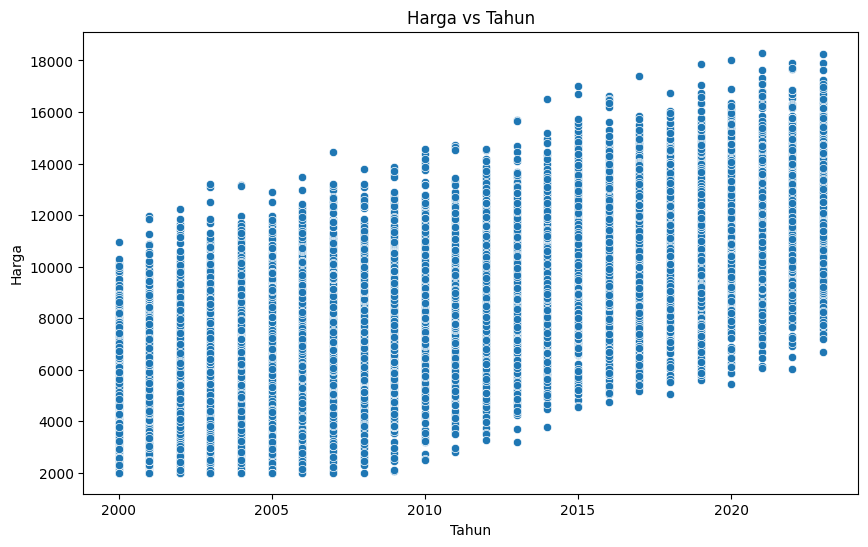

In [18]:
if 'Year' in df.columns:
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x='Year', y='Price', data=df)
    plt.title('Harga vs Tahun')
    plt.xlabel('Tahun')
    plt.ylabel('Harga')
    plt.show()

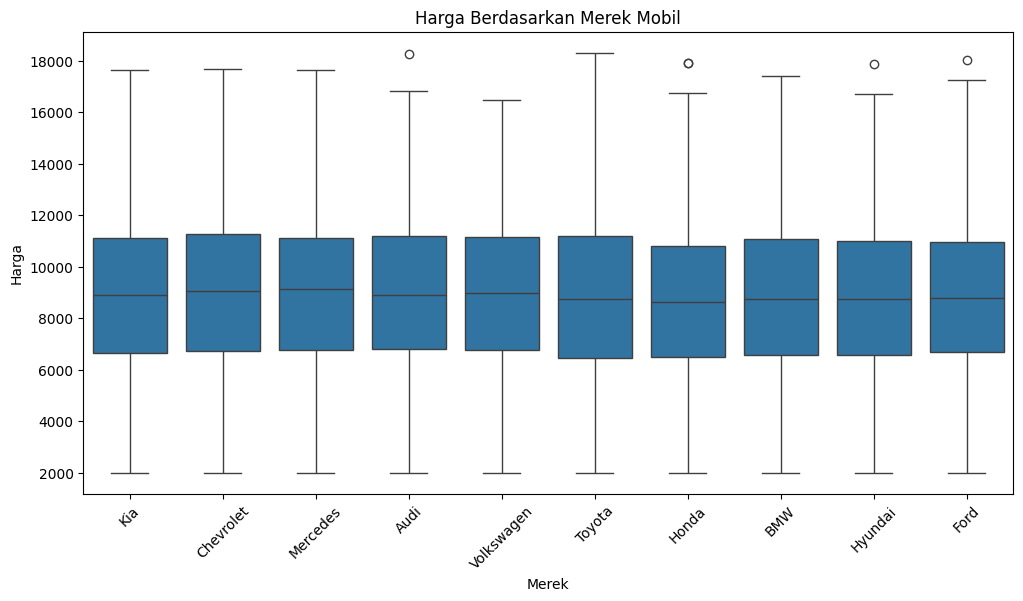

In [19]:
if 'Brand' in df.columns:
    plt.figure(figsize=(12, 6))
    sns.boxplot(x='Brand', y='Price', data=df)
    plt.xticks(rotation=45)
    plt.title('Harga Berdasarkan Merek Mobil')
    plt.xlabel('Merek')
    plt.ylabel('Harga')
    plt.show()